In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

In [3]:
df = pd.read_csv("../data/ai4i2020_augmented.csv")  
df.head()

,UDI,Product ID,Quality Type,Machine Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Cutting force [N],Tool flank wear VB [mm],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,Turning,298.1,308.6,1551,42.8,1426.4,0.005,0,0,0,0,0,0
1,2,L47181,L,Milling,298.2,308.7,1408,46.3,2963.7,0.009,0,0,0,0,0,0
2,3,L47182,L,Turning,298.1,308.5,1498,49.4,1620.1,0.011,0,0,0,0,0,0
3,4,L47183,L,Turning,298.2,308.6,1433,39.5,1298.9,0.012,0,0,0,0,0,0
4,5,L47184,L,Milling,298.2,308.7,1408,40.0,2387.7,0.016,0,0,0,0,0,0


In [4]:
df = df.rename(columns={
    "Quality Type": "quality_type",
    "Machine Type": "machine_type",
    "Air temperature [K]": "air_temp",
    "Process temperature [K]": "process_temp",
    "Rotational speed [rpm]": "rpm",
    "Torque [Nm]": "torque",
    "Cutting force [N]": "cutting_force",
    "Tool flank wear VB [mm]": "flank_wear",
    "Machine failure": "failure"
})
df.columns

Index(['UDI', 'Product ID', 'quality_type', 'machine_type', 'air_temp',
       'process_temp', 'rpm', 'torque', 'cutting_force', 'flank_wear',
       'failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF'],
      dtype='str')

In [5]:
df["failure"].value_counts()

failure
0    9645
1     355
Name: count, dtype: int64

In [6]:
df["failure"].value_counts(normalize=True) * 100

failure
0    96.45
1     3.55
Name: proportion, dtype: float64

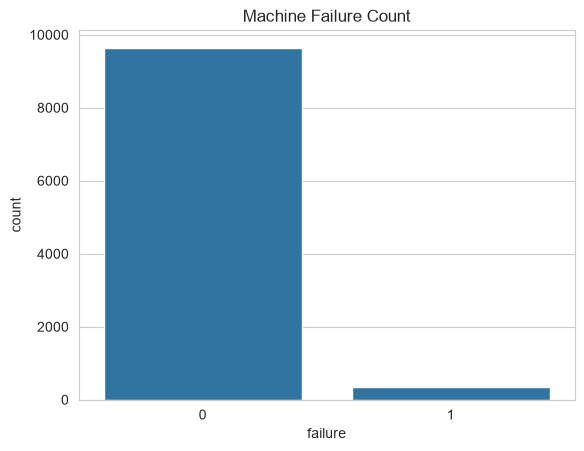

In [7]:
sns.countplot(x="failure", data=df)
plt.title("Machine Failure Count")
plt.show()

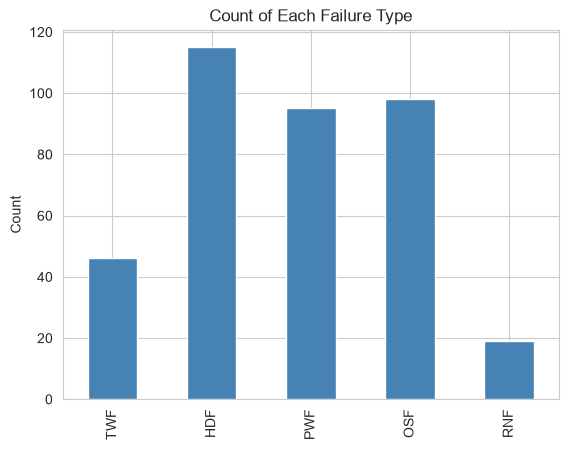

In [8]:
failure_types = ["TWF", "HDF", "PWF", "OSF", "RNF"]
df[failure_types].sum()
df[failure_types].sum().plot(kind="bar", color="steelblue")
plt.title("Count of Each Failure Type")
plt.ylabel("Count")
plt.show()

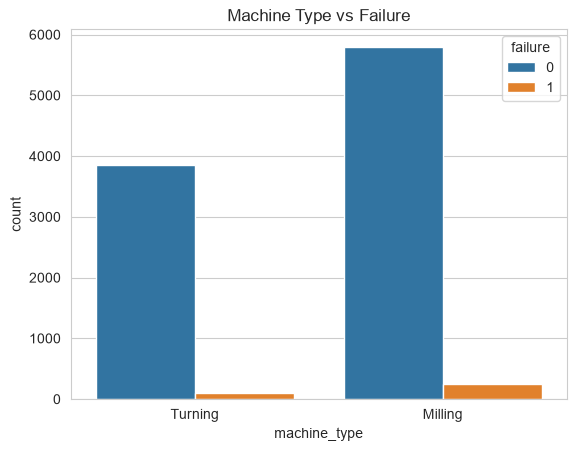

In [10]:
sns.countplot(x="machine_type", hue="failure", data=df)
plt.title("Machine Type vs Failure")
plt.show()

In [11]:
df.groupby("machine_type")["failure"].mean() * 100

machine_type
Milling    4.199735
Turning    2.555668
Name: failure, dtype: float64

In [12]:
df.groupby("quality_type")["failure"].mean() * 100

quality_type
H    2.392822
L    4.150000
M    2.736069
Name: failure, dtype: float64

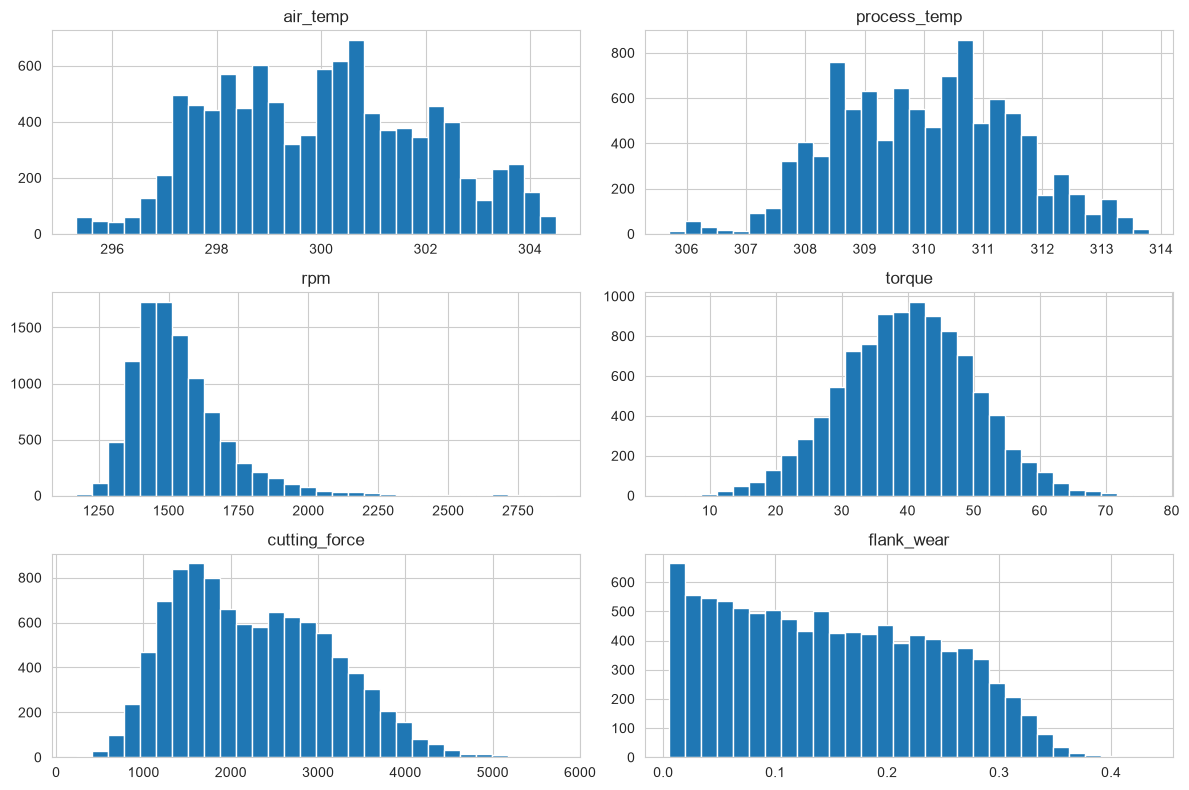

In [13]:
features = ["air_temp", "process_temp", "rpm", "torque", "cutting_force", "flank_wear"]

df[features].hist(bins=30, figsize=(12, 8))
plt.tight_layout()
plt.show()

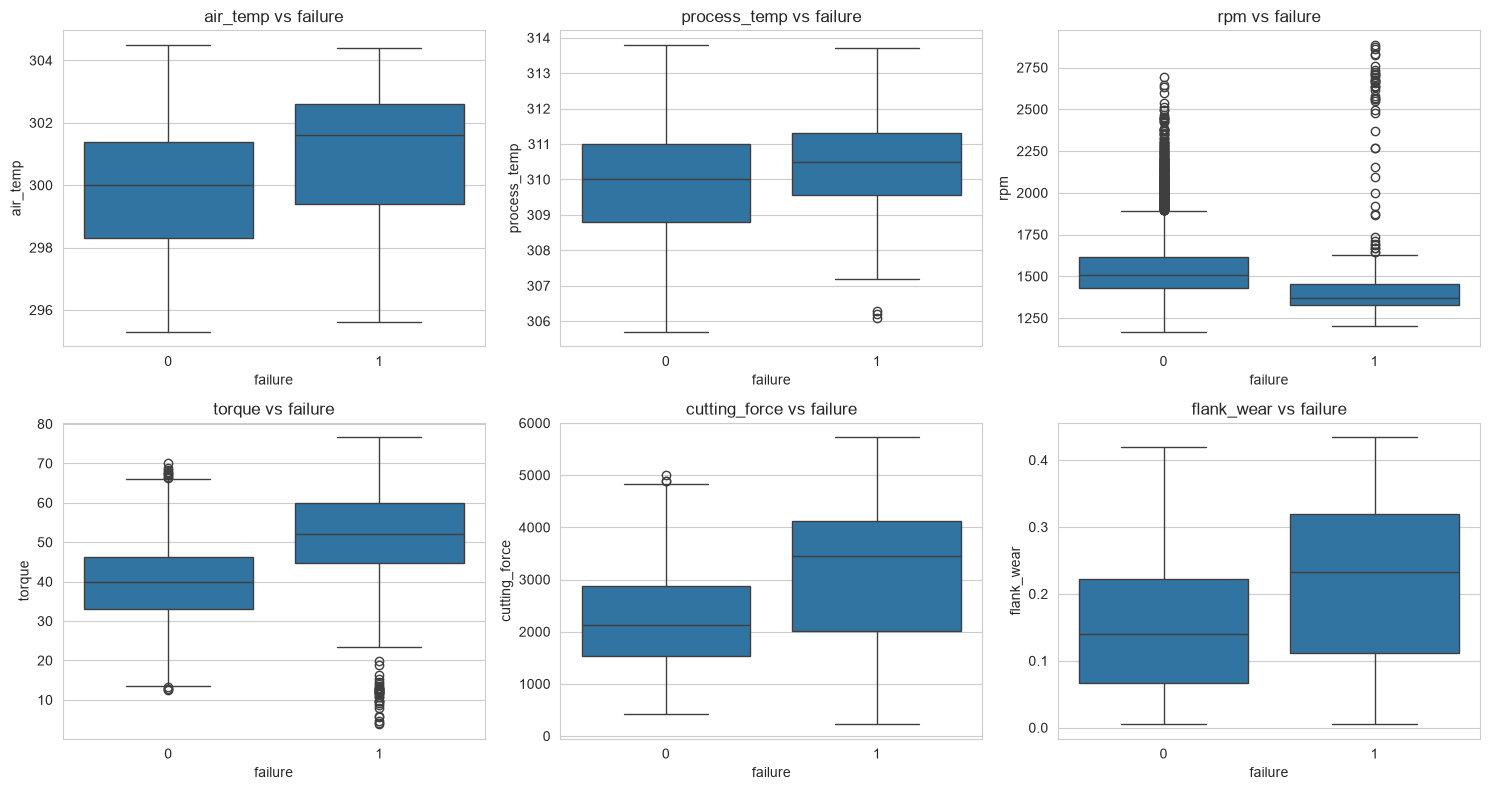

In [14]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.ravel()

for i, col in enumerate(features):
    sns.boxplot(x="failure", y=col, data=df, ax=axes[i])
    axes[i].set_title(f"{col} vs failure")

plt.tight_layout()
plt.show()

In [15]:
df.groupby("failure")[features].mean()

,air_temp,process_temp,rpm,torque,cutting_force,flank_wear
failure,,,,,,
0,299.969715,309.992701,1540.184655,39.643287,2218.660508,0.146684
1,300.961690,310.354930,1500.507042,49.322817,3098.585634,0.212268


In [16]:
df.groupby("failure")[features].mean()

,air_temp,process_temp,rpm,torque,cutting_force,flank_wear
failure,,,,,,
0,299.969715,309.992701,1540.184655,39.643287,2218.660508,0.146684
1,300.961690,310.354930,1500.507042,49.322817,3098.585634,0.212268


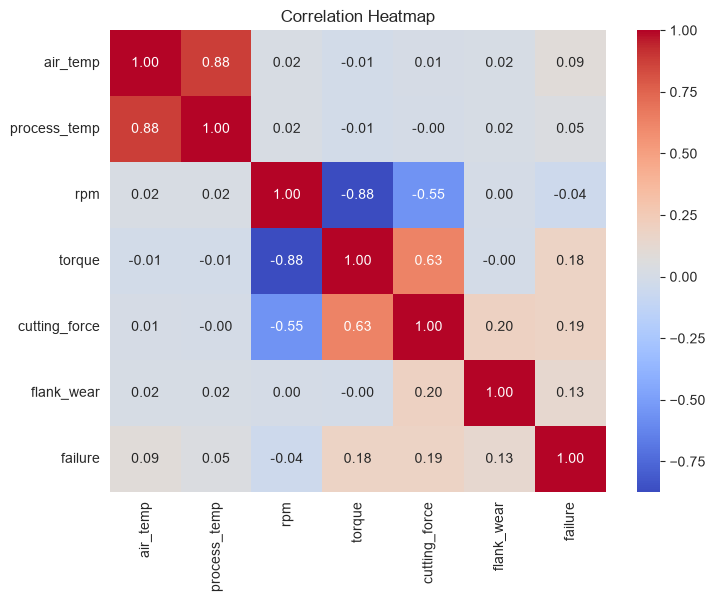

In [17]:
plt.figure(figsize=(8, 6))
sns.heatmap(df[features + ["failure"]].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

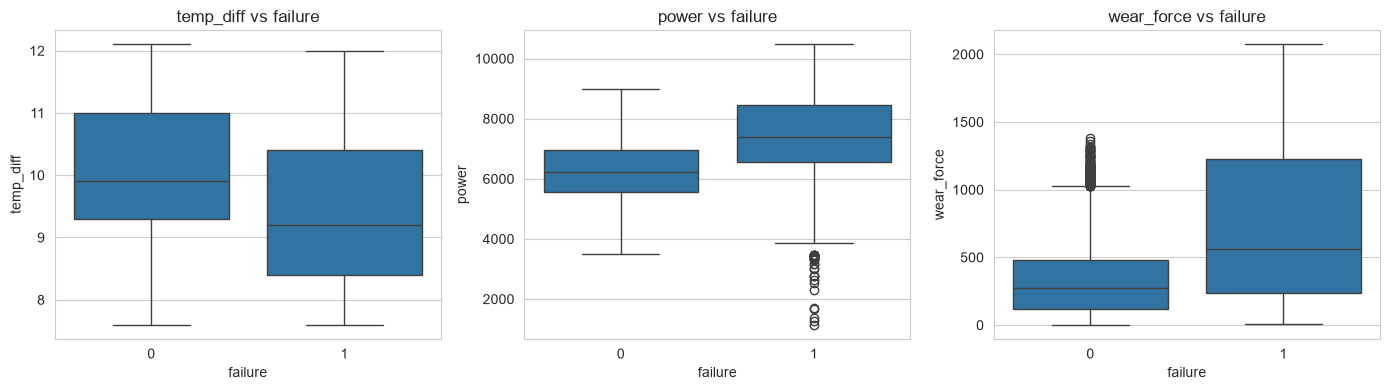

In [21]:
df["temp_diff"] = df["process_temp"] - df["air_temp"]
df["power"] = df["torque"] * df["rpm"] * 2 * np.pi / 60
df["wear_force"] = df["flank_wear"] * df["cutting_force"]

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, ["temp_diff", "power", "wear_force"]):
    sns.boxplot(x="failure", y=col, data=df, ax=ax)
    ax.set_title(f"{col} vs failure")

plt.tight_layout()
plt.show()

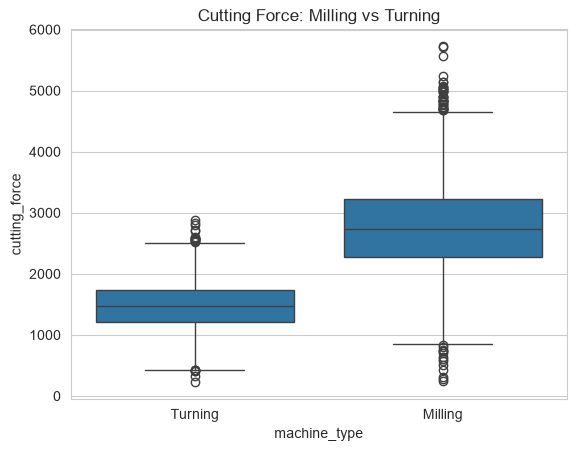

In [19]:
sns.boxplot(x="machine_type", y="cutting_force", data=df)
plt.title("Cutting Force: Milling vs Turning")
plt.show()

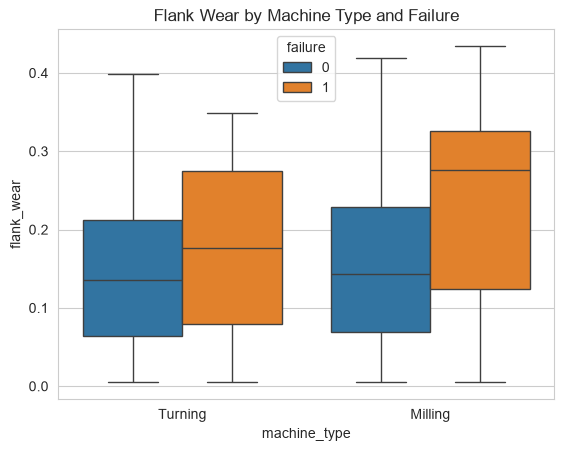

In [20]:
sns.boxplot(x="machine_type", y="flank_wear", hue="failure", data=df)
plt.title("Flank Wear by Machine Type and Failure")
plt.show()